# 1 · Exploring RAVDESS speech

The [RAVDESS](https://zenodo.org/records/1188976) speech set has 1,440 clips: 24 professional actors (12 female, 12 male) each say two
fixed English sentences ("Kids are talking by the door", "Dogs are sitting by the door") in 8 emotions, at two intensities, twice.

This notebook looks at what the data actually contains, and at the facts that drive the modelling decisions in notebook 2:
class balance, how many *speakers* (not clips) there are, how much silence the recordings have, and which acoustic cues separate
the emotions.

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed

from emotion.data import EMOTIONS, SAMPLE_RATE, load_audio, load_index

sns.set_theme(style="whitegrid")
df = load_index()  # downloads the dataset on first run
df.head()

,path,emotion,intensity,statement,repetition,actor,gender,split,label
0,/Users/joaoliveirarruda/dev/miniprojeto2/data/...,neutral,normal,1,1,1,male,train,5
1,/Users/joaoliveirarruda/dev/miniprojeto2/data/...,neutral,normal,1,2,1,male,train,5
2,/Users/joaoliveirarruda/dev/miniprojeto2/data/...,neutral,normal,2,1,1,male,train,5
3,/Users/joaoliveirarruda/dev/miniprojeto2/data/...,neutral,normal,2,2,1,male,train,5
4,/Users/joaoliveirarruda/dev/miniprojeto2/data/...,calm,normal,1,1,1,male,train,1


## Class balance

Every emotion has 192 clips except **neutral**, which has no "strong" intensity and so has half as many. That's mild enough that
plain accuracy is still meaningful, but we also report macro-F1 so the smaller class counts equally.

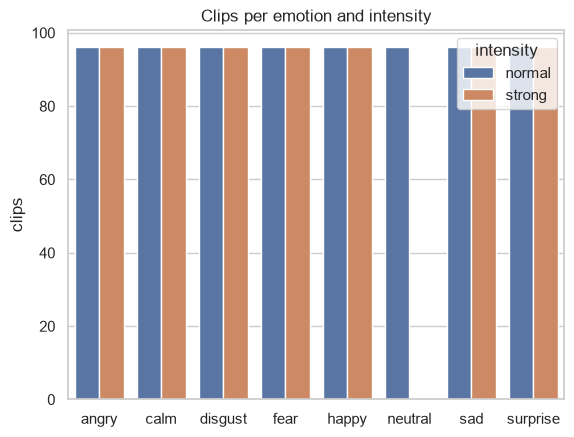

In [2]:
ax = sns.countplot(data=df, x="emotion", hue="intensity", order=EMOTIONS)
ax.set(title="Clips per emotion and intensity", xlabel="", ylabel="clips");

## It's 24 speakers, not 1,440 independent samples

Each actor contributes 60 clips with the same voice, microphone and room. If clips of one actor land in both train and test, a
model can score well by recognising *the actor* rather than the emotion. The original version of this project split clips at
random (and augmented before splitting, so near-identical copies of a clip were on both sides), which inflated its accuracy.

Here the split is by actor, fixed in `emotion/data.py`, and balanced by gender:

In [3]:
df.groupby("split").agg(clips=("path", "size"), actors=("actor", lambda a: sorted(set(a))),
                        female=("gender", lambda g: (g == "female").sum()))

,clips,actors,female
split,,,
test,360,"[19, 20, 21, 22, 23, 24]",180
train,840,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]",420
val,240,"[15, 16, 17, 18]",120


## Silence and duration

Almost half of every recording is silence: clips average 3.7 s, but trimming the silence at both ends (`librosa.effects.trim`,
30 dB) leaves 1.9 s of actual speech on average, and 2.1 s for three quarters of them. That's why the model is trained on **3-second windows**: one window covers a whole
utterance, and it's also the window the web app classifies from the microphone.

,raw,trimmed
count,1440.00,1440.00
mean,3.70,1.90
std,0.34,0.42
min,2.94,1.15
25%,3.47,1.60
50%,3.67,1.79
75%,3.87,2.11
max,5.27,4.25


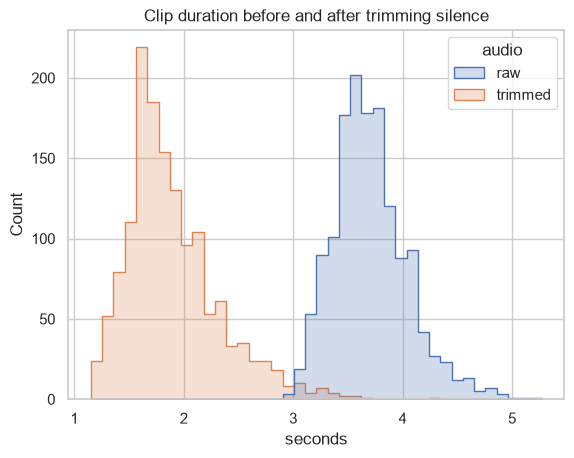

In [4]:
def durations(path):
    raw = librosa.get_duration(path=path)
    return raw, len(load_audio(path)) / SAMPLE_RATE

d = pd.DataFrame(Parallel(n_jobs=-1)(delayed(durations)(p) for p in df.path), columns=["raw", "trimmed"])
ax = sns.histplot(d.melt(var_name="audio", value_name="seconds"), x="seconds", hue="audio", bins=40, element="step")
ax.set(title="Clip duration before and after trimming silence")
d.describe().round(2)

## What separates the emotions

Two cheap cues already tell a lot: **loudness** (RMS energy) and **pitch** (median fundamental frequency). High-arousal emotions
(angry, fear, happy, surprise) are louder and higher; calm, neutral and sad are quieter and lower, and disgust sits in between. Pitch also differs a lot by
gender, which is one more reason to keep both genders in every split.

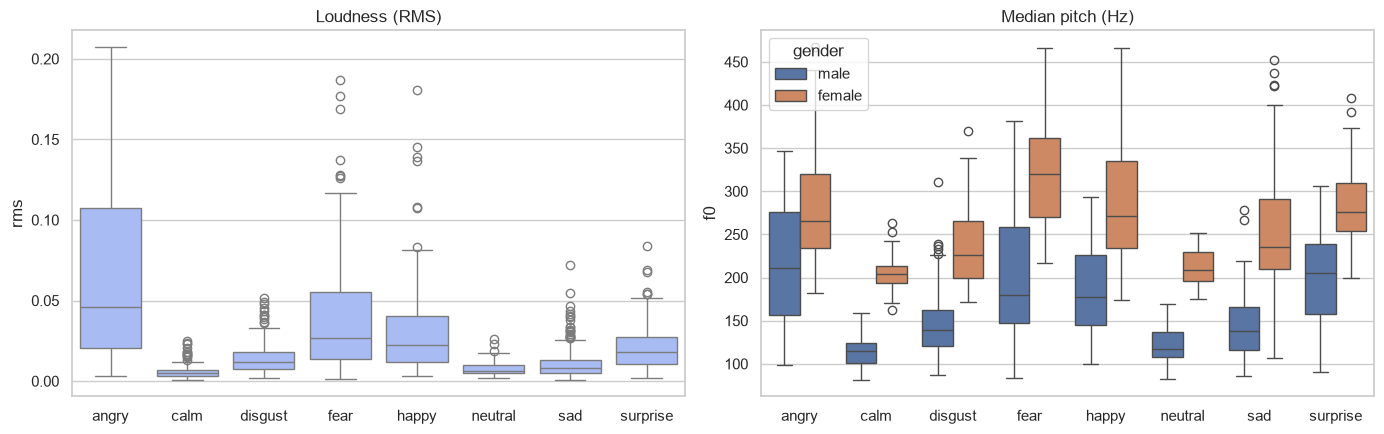

In [5]:
def cues(path):
    y = load_audio(path)
    f0 = librosa.yin(y, fmin=60, fmax=500, sr=SAMPLE_RATE)
    return np.sqrt(np.mean(y**2)), np.median(f0)

cue = df[["emotion", "gender"]].copy()
cue[["rms", "f0"]] = Parallel(n_jobs=-1)(delayed(cues)(p) for p in df.path)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=cue, x="emotion", y="rms", order=EMOTIONS, ax=axes[0], color="#9db4ff")
sns.boxplot(data=cue, x="emotion", y="f0", hue="gender", order=EMOTIONS, ax=axes[1])
axes[0].set(title="Loudness (RMS)", xlabel="")
axes[1].set(title="Median pitch (Hz)", xlabel="")
fig.tight_layout()

The cues overlap, though, especially within the low-arousal group (calm vs. neutral vs. sad) and within the high-arousal one
(happy vs. surprise vs. fear). Here is the same actor saying the same sentence in three emotions:

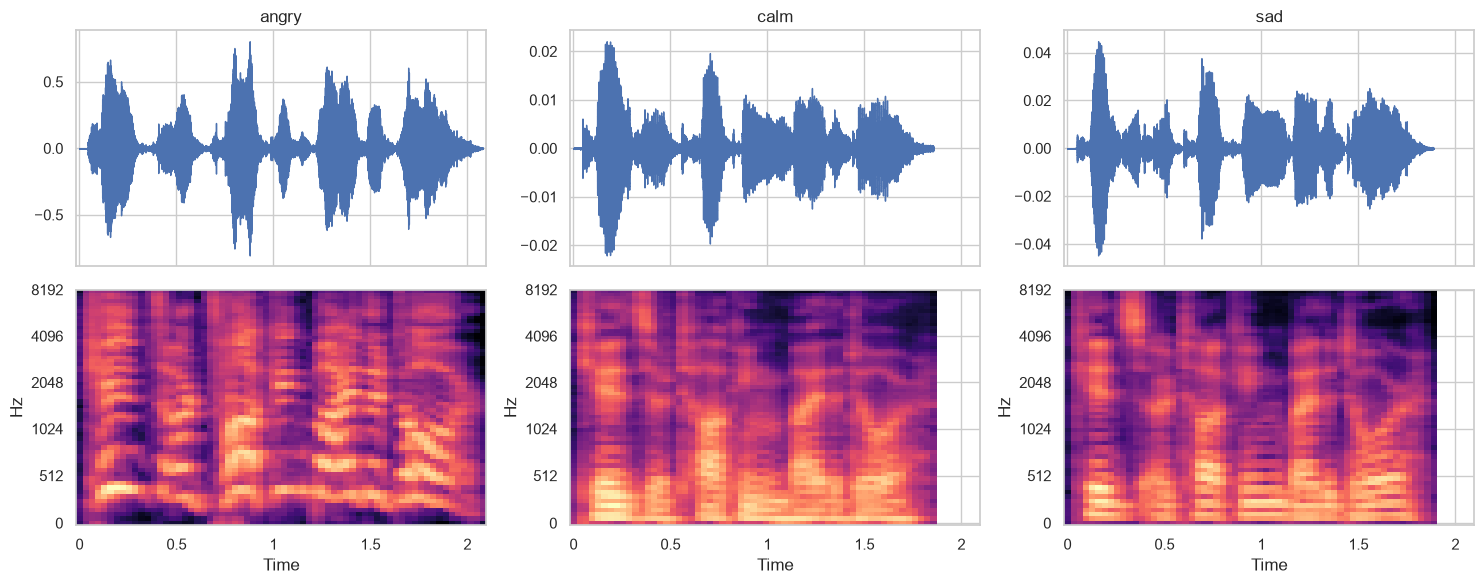

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for col, emotion in enumerate(["angry", "calm", "sad"]):
    row = df.query("actor == 1 and statement == 1 and repetition == 1 and emotion == @emotion")
    row = row[row.intensity == ("normal" if emotion == "neutral" else "strong")].iloc[0]
    y = load_audio(row.path)
    librosa.display.waveshow(y, sr=SAMPLE_RATE, ax=axes[0, col])
    axes[0, col].set(title=emotion, xlabel="")
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_mels=64), ref=np.max)
    librosa.display.specshow(mel, sr=SAMPLE_RATE, x_axis="time", y_axis="mel", ax=axes[1, col])
fig.tight_layout()

## Takeaways

- **Evaluate by speaker.** With only 24 voices, a random clip split measures speaker memorisation. All models in notebook 2 use
  the same fixed actor split (14 train / 4 val / 6 test).
- **Trim silence, use ~3 s windows.** That covers an utterance and matches what the live app can afford to classify.
- **Arousal is easy, valence is hard.** Loudness and pitch separate "energetic" from "quiet" emotions, but telling happy from
  angry, or calm from sad, needs richer cues: that's where a pretrained speech model should help.
- **Acted, scripted, English, studio audio.** Whatever we measure here is an upper bound for real-world use.